<a href="https://colab.research.google.com/github/madhukshara09/Codomax-Data-Science-Intern/blob/main/module05_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Loaded: 7,043 rows x 21 columns

First 5 Records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Cleaned 11 blank entries in 'TotalCharges'. Overall Churn Rate: 26.54%

--- CHURN RATE & AVG CHARGES BY CONTRACT TYPE ---
                Total_Customers  Churn_Rate_Pct  Avg_Monthly_Charges  \
Contract                                                               
Month-to-month             3875           42.71                66.40   
One year                   1473           11.27                65.05   
Two year                   1695            2.83                60.77   

                Avg_Tenure_Months  
Contract                           
Month-to-month               18.0  
One year                     42.0  
Two year                     56.7  

--- CHURN RATE BY INTERNET SERVICE ---
                 Total_Customers  Churn_Rate_Pct  Avg_Monthly_Charges
InternetService                                                      
DSL                         2421           18.96                58.10
Fiber optic                 3096           41.89                91.50
No              

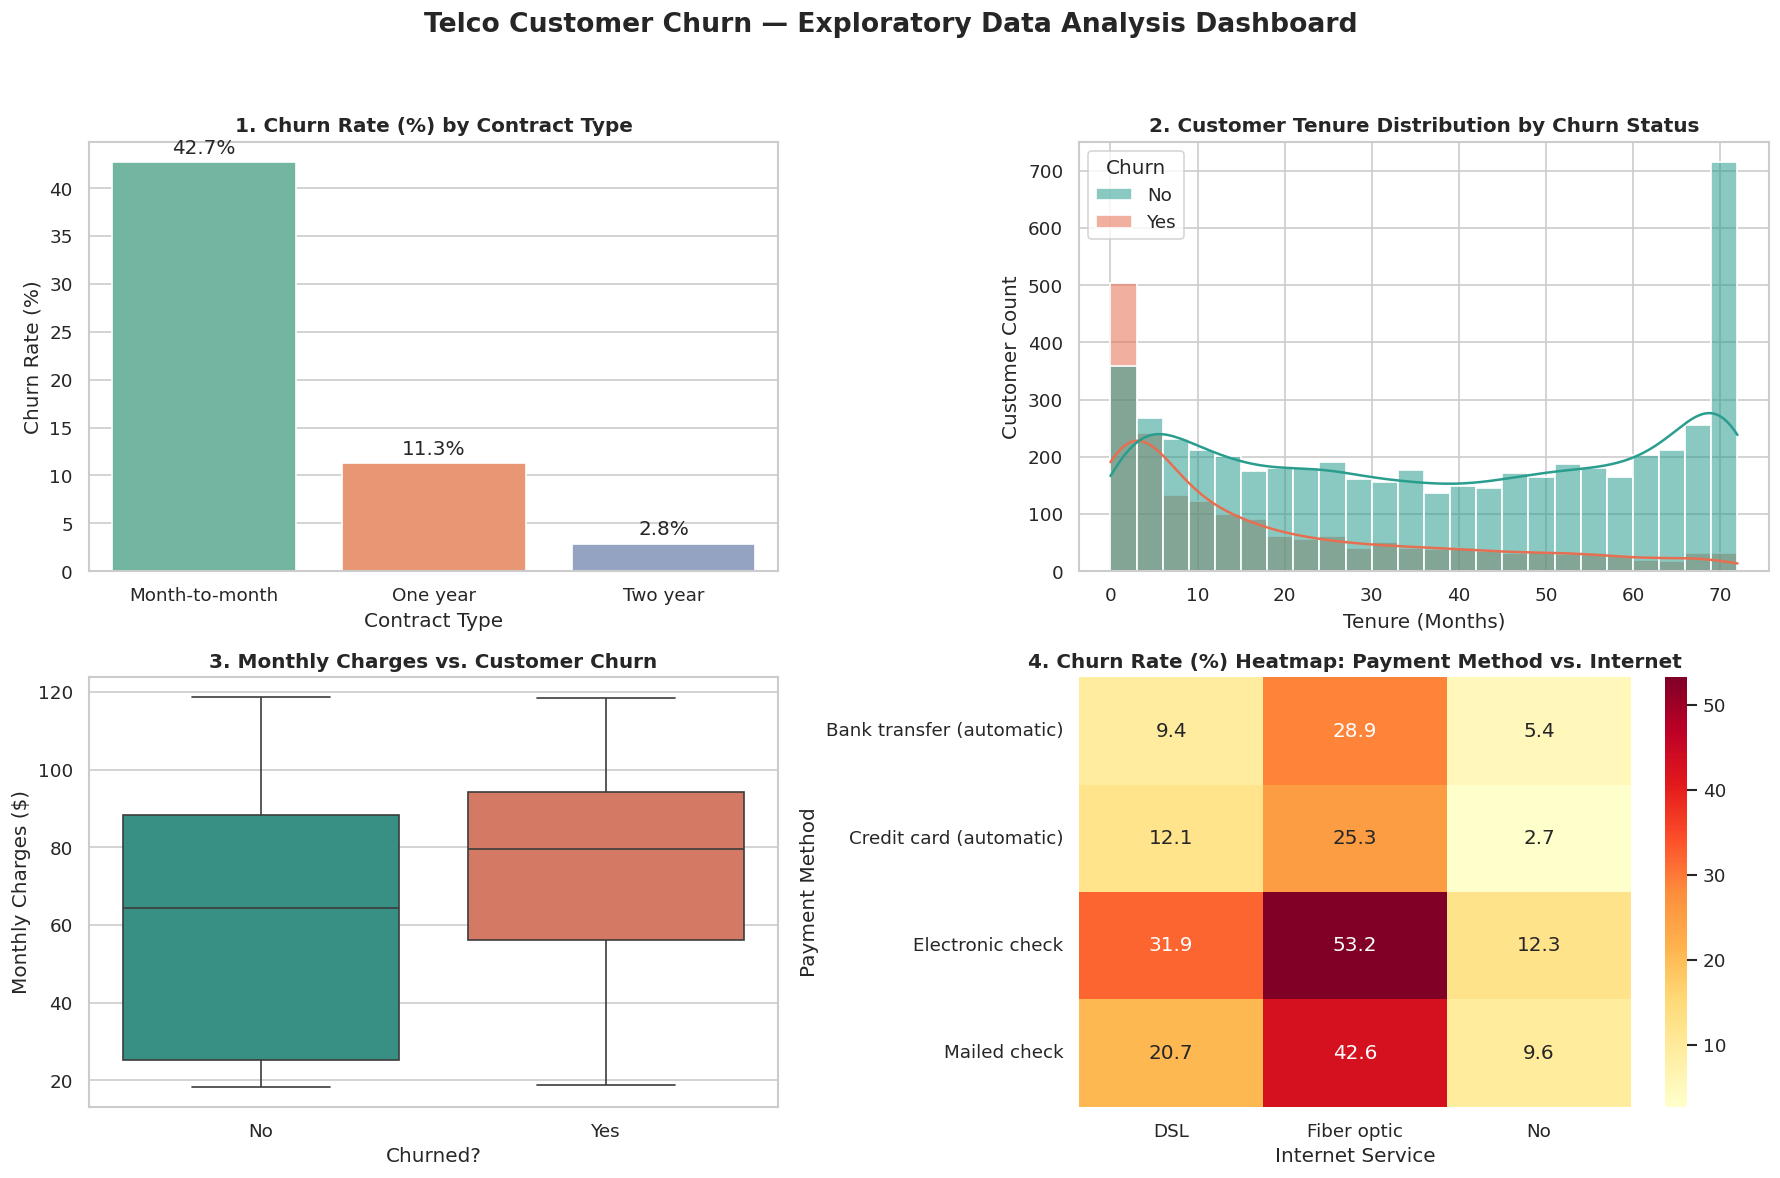

In [1]:
# ==========================================
# OBJECTIVE 1: Load & Inspect a Real-World Public Dataset (Telco Customer Churn)
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 120

# Load public real-world Telco Customer Churn dataset (7,043 customers)
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print(f"Dataset Loaded: {df.shape[0]:,} rows x {df.shape[1]} columns\n")
print("First 5 Records:")
display(df.head())

# Data Cleaning: Convert 'TotalCharges' to numeric (contains blank spaces for new customers)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing_charges = df["TotalCharges"].isnull().sum()
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["Churn_Flag"] = df["Churn"].map({"Yes": 1, "No": 0})

print(f"\nCleaned {missing_charges} blank entries in 'TotalCharges'. Overall Churn Rate: {df['Churn_Flag'].mean()*100:.2f}%\n")


# ==========================================
# OBJECTIVE 2: Exploratory Data Analysis & Key Metrics
# ==========================================
print("--- CHURN RATE & AVG CHARGES BY CONTRACT TYPE ---")
contract_summary = df.groupby("Contract").agg(
    Total_Customers=("customerID", "count"),
    Churn_Rate_Pct=("Churn_Flag", lambda x: round(x.mean() * 100, 2)),
    Avg_Monthly_Charges=("MonthlyCharges", lambda x: round(x.mean(), 2)),
    Avg_Tenure_Months=("tenure", lambda x: round(x.mean(), 1))
)
print(contract_summary)

print("\n--- CHURN RATE BY INTERNET SERVICE ---")
internet_summary = df.groupby("InternetService").agg(
    Total_Customers=("customerID", "count"),
    Churn_Rate_Pct=("Churn_Flag", lambda x: round(x.mean() * 100, 2)),
    Avg_Monthly_Charges=("MonthlyCharges", lambda x: round(x.mean(), 2))
)
print(internet_summary)


# ==========================================
# OBJECTIVE 3: Create Visualizations & Summarize Findings
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("Telco Customer Churn — Exploratory Data Analysis Dashboard", fontsize=16, fontweight="bold", y=0.98)

# 1. Churn Rate by Contract Type
contract_order = ["Month-to-month", "One year", "Two year"]
sns.barplot(
    data=df, x="Contract", y="Churn_Flag", order=contract_order,
    estimator=lambda x: np.mean(x) * 100, errorbar=None, hue="Contract", legend=False, ax=axes[0, 0]
)
axes[0, 0].set_title("1. Churn Rate (%) by Contract Type", fontweight="bold")
axes[0, 0].set_ylabel("Churn Rate (%)")
axes[0, 0].set_xlabel("Contract Type")
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt="%.1f%%", padding=3)

# 2. Tenure Distribution: Retained vs. Churned Customers
sns.histplot(
    data=df, x="tenure", hue="Churn", bins=24, kde=True,
    palette={"No": "#2a9d8f", "Yes": "#e76f51"}, alpha=0.55, ax=axes[0, 1]
)
axes[0, 1].set_title("2. Customer Tenure Distribution by Churn Status", fontweight="bold")
axes[0, 1].set_xlabel("Tenure (Months)")
axes[0, 1].set_ylabel("Customer Count")

# 3. Monthly Charges Distribution by Churn Status (Boxplot)
sns.boxplot(
    data=df, x="Churn", y="MonthlyCharges", hue="Churn",
    palette={"No": "#2a9d8f", "Yes": "#e76f51"}, legend=False, ax=axes[1, 0]
)
axes[1, 0].set_title("3. Monthly Charges vs. Customer Churn", fontweight="bold")
axes[1, 0].set_xlabel("Churned?")
axes[1, 0].set_ylabel("Monthly Charges ($)")

# 4. Churn Rate by Internet Service & Payment Method Heatmap
pivot_churn = df.pivot_table(index="PaymentMethod", columns="InternetService", values="Churn_Flag", aggfunc="mean") * 100
sns.heatmap(pivot_churn, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[1, 1])
axes[1, 1].set_title("4. Churn Rate (%) Heatmap: Payment Method vs. Internet", fontweight="bold")
axes[1, 1].set_xlabel("Internet Service")
axes[1, 1].set_ylabel("Payment Method")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("module5_telco_churn_dashboard.png", dpi=150)
plt.show()

### Summary of Key Findings & Business Recommendations
1. **Contract Lock-In Drives Retention:** Customers on **Month-to-month contracts** churn at **42.7%**, compared to **11.3%** for One-year and just **2.8%** for Two-year contracts. Offering discounted annual upgrades to month-to-month users at month 3 is the highest-leverage retention play.
2. **Early-Lifecycle Vulnerability:** The tenure histogram reveals a sharp spike in churn during the **first 1–6 months**, whereas customers who stay past 24 months rarely leave. Stronger onboarding support in the first 90 days can significantly reduce early attrition.
3. **Price Sensitivity & Fiber Optic Churn:** Churned customers pay a higher median monthly bill (~$79.65 vs. ~$64.43 for retained customers), with **Fiber optic + Electronic check** users exceeding a **50% churn rate**. Bundling loyalty perks or auto-pay discounts for high-tier Fiber customers directly targets this high-risk segment.